# 04 - Clustering & Specialist vs Generalist

**Cel**:
1. Zgrupować organizmy na podstawie macierzy transferu z notatnika 03.
2. Zbudować meta-predyktor przypisujący nowe organizmy do klastrów na podstawie cech genomu.
3. Porównać modele **specjalistyczne** (trenowane na klastrze) vs **generalistyczne** (wszystkie dane) vs **solo**.

**Wymagania**: Notatnik 03 musi być uruchomiony (generuje `transfer_matrix.npy`).

In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

_here = Path().resolve()
REPO_ROOT = next(p for p in [_here, *_here.parents] if (p / 'Cargo.toml').exists())

RESULTS_DIR = REPO_ROOT / 'experiments' / 'transfer' / 'results'
CONFIG_PATH = REPO_ROOT / 'experiments' / 'transfer' / 'config' / 'organisms.yaml'

sys.path.insert(0, str(REPO_ROOT / 'ml' / 'experiments'))

from utils.results_io import (
    collect_solo_evals,
    collect_finetune_evals,
    build_transfer_matrix,
    load_training_history,
)
from utils.plot_helpers import (
    plot_transfer_heatmap,
    plot_dendrogram,
    plot_model_comparison_bars,
)

with open(CONFIG_PATH) as f:
    config = yaml.safe_load(f)
organisms = config['organisms']
names     = list(organisms.keys())
labels    = [organisms[n]['label'] for n in names]

print('REPO_ROOT:', REPO_ROOT)
print('Organisms:', names)

REPO_ROOT: /home/ziutek/fstudies/inz/dna-assembler-ml
Organisms: ['ecoli', 'cerevisiae', 'bsubtilis', 'mtuberculosis', 'hpylori']


## 1 - Load transfer matrix

In [11]:
matrix_path = RESULTS_DIR / 'transfer_matrix.npy'

if matrix_path.exists():
    transfer_matrix = np.load(matrix_path)
    print('Loaded transfer matrix from', matrix_path)
else:
    # Recompute from raw JSONs if NB 03 wasn't run
    solo_df = collect_solo_evals(RESULTS_DIR, names)
    ft_df   = collect_finetune_evals(RESULTS_DIR, names)
    transfer_matrix = build_transfer_matrix(ft_df, solo_df, names)
    print('Recomputed transfer matrix.')

print('Shape:', transfer_matrix.shape)
pd.DataFrame(transfer_matrix, index=names, columns=names).round(4)

Loaded transfer matrix from /home/ziutek/fstudies/inz/dna-assembler-ml/experiments/transfer/results/transfer_matrix.npy
Shape: (5, 5)


,ecoli,cerevisiae,bsubtilis,mtuberculosis,hpylori
ecoli,NaN,0.0034,0.0323,-0.0250,0.0263
cerevisiae,-0.0563,NaN,0.0766,0.0347,0.0213
bsubtilis,-0.0462,-0.0169,NaN,-0.0231,-0.0526
mtuberculosis,-0.0596,-0.0084,-0.0173,NaN,-0.0437
hpylori,-0.0417,-0.0263,0.0000,-0.0231,NaN


## 2 - Distance matrix & hierarchical clustering

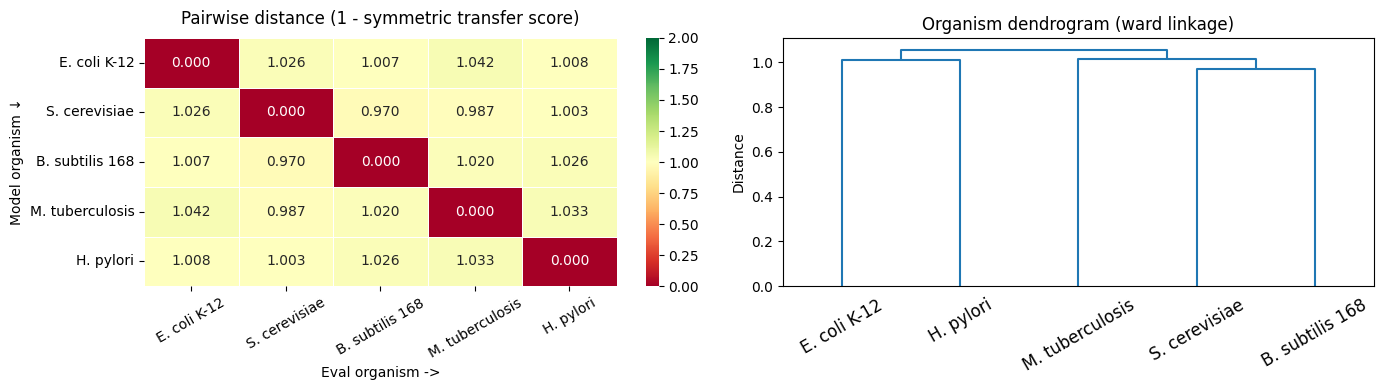

In [12]:
tm = np.nan_to_num(transfer_matrix, nan=0.0)
sym_score = (tm + tm.T) / 2
distance_matrix = 1.0 - sym_score
np.fill_diagonal(distance_matrix, 0.0)

condensed = squareform(distance_matrix, checks=False)
linkage = hierarchy.linkage(condensed, method='ward')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_transfer_heatmap(
    distance_matrix, labels,
    title='Pairwise distance (1 - symmetric transfer score)',
    ax=axes[0], vmin=0.0, vmax=2.0, center=1.0,
    fmt='.3f',
)

plot_dendrogram(linkage, labels, ax=axes[1],
                title='Organism dendrogram (ward linkage)')

plt.tight_layout()
plt.show()

## 3 - Cluster assignment

Choose the cut height visually from the dendrogram above.

Number of clusters at cut_height=1.0: 4


,organism,label,cluster,gc_content,genome_mbp
0,ecoli,E. coli K-12,1,50.8,4.6
4,hpylori,H. pylori,2,38.9,1.7
2,bsubtilis,B. subtilis 168,3,43.5,4.2
1,cerevisiae,S. cerevisiae,3,38.0,12.1
3,mtuberculosis,M. tuberculosis,4,65.6,4.4


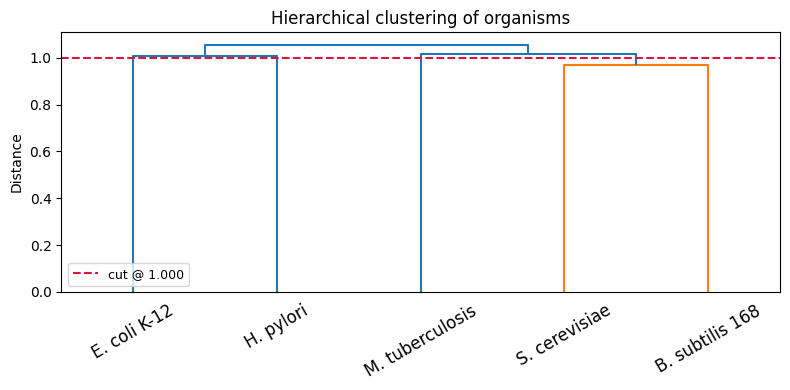

In [13]:
CUT_HEIGHT = 1.0

cluster_ids = hierarchy.fcluster(linkage, t=CUT_HEIGHT, criterion='distance')
n_clusters  = len(set(cluster_ids))

cluster_df = pd.DataFrame({
    'organism':   names,
    'label':      labels,
    'cluster':    cluster_ids,
    'gc_content': [organisms[n]['gc_content']      for n in names],
    'genome_mbp': [organisms[n]['genome_size_mbp'] for n in names],
})

print(f'Number of clusters at cut_height={CUT_HEIGHT}: {n_clusters}')
display(cluster_df.sort_values('cluster'))

fig, ax = plt.subplots(figsize=(8, 4))
plot_dendrogram(linkage, labels, ax=ax, cut_height=CUT_HEIGHT)
plt.tight_layout()
plt.show()

## 4 - Are the clusters biologically meaningful?

Check whether organisms in the same cluster share genomic properties.

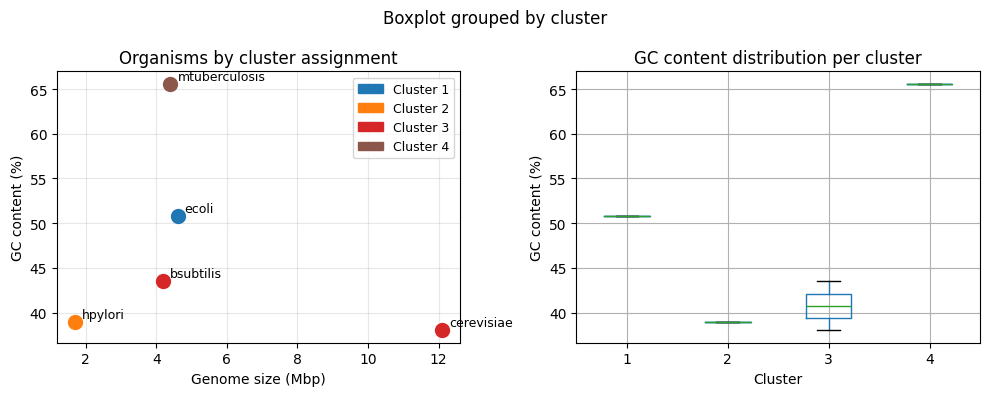

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

colors = plt.cm.tab10(np.linspace(0, 0.5, n_clusters))
color_map = {c: colors[i] for i, c in enumerate(sorted(set(cluster_ids)))}

for _, row in cluster_df.iterrows():
    c = color_map[row['cluster']]
    axes[0].scatter(row['genome_mbp'], row['gc_content'], color=c, s=100, zorder=3)
    axes[0].annotate(row['organism'], (row['genome_mbp'], row['gc_content']),
                     textcoords='offset points', xytext=(5, 3), fontsize=9)

from matplotlib.patches import Patch
legend_handles = [Patch(color=color_map[c], label=f'Cluster {c}')
                  for c in sorted(set(cluster_ids))]
axes[0].legend(handles=legend_handles, fontsize=9)
axes[0].set_xlabel('Genome size (Mbp)')
axes[0].set_ylabel('GC content (%)')
axes[0].set_title('Organisms by cluster assignment')
axes[0].grid(True, alpha=0.3)

cluster_df.boxplot(column='gc_content', by='cluster', ax=axes[1])
axes[1].set_title('GC content distribution per cluster')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('GC content (%)')

plt.tight_layout()
plt.show()

## 5 - Meta-predictor for new organisms

Train a tiny classifier: `[GC%, log(genome_size_Mbp)] -> cluster_id`.  
Given a new organism's reference genome stats, predict which specialist model to use.

> **Note**: With only 5 organisms this is a proof-of-concept, not a production classifier.

In [15]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut
from sklearn.pipeline import make_pipeline
import warnings

X = cluster_df[['gc_content', 'genome_mbp']].copy()
X['log_genome'] = np.log(X['genome_mbp'])
X = X[['gc_content', 'log_genome']].values
y = cluster_df['cluster'].values

k = min(3, len(names) - 1)
clf = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

loo = LeaveOneOut()
preds_loo = []
for train_idx, test_idx in loo.split(X):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        clf.fit(X[train_idx], y[train_idx])
        preds_loo.append(clf.predict(X[test_idx])[0])

loo_acc = np.mean(np.array(preds_loo) == y)
print(f'LOO accuracy: {loo_acc:.2f}  (N={len(names)}, k={k}-NN)')
print()
print('LOO predictions:')
for org, pred, true in zip(names, preds_loo, y):
    mark = '[OK]' if pred == true else '[X]'
    print(f'  {org:20s}  predicted={pred}  true={true}  {mark}')

LOO accuracy: 0.00  (N=5, k=3-NN)

LOO predictions:
  ecoli                 predicted=2  true=1  [X]
  cerevisiae            predicted=1  true=3  [X]
  bsubtilis             predicted=1  true=3  [X]
  mtuberculosis         predicted=1  true=4  [X]
  hpylori               predicted=1  true=2  [X]


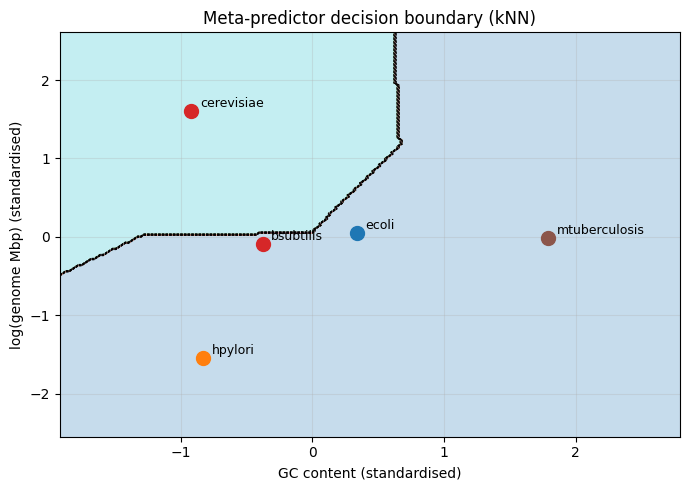

In [16]:
clf.fit(X, y)  # fit on all data for decision boundary visualisation

scaler = clf.named_steps['standardscaler']
X_scaled = scaler.transform(X)

xx, yy = np.meshgrid(
    np.linspace(X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1, 200),
    np.linspace(X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1, 200),
)
Z = clf.named_steps['kneighborsclassifier'].predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
ax.contourf(xx, yy, Z, alpha=0.25, cmap='tab10')
ax.contour(xx, yy, Z, colors='k', linewidths=0.5, linestyles='--')

for i, (xs, ys, org) in enumerate(zip(X_scaled[:, 0], X_scaled[:, 1], names)):
    ax.scatter(xs, ys, color=color_map[y[i]], s=100, zorder=5)
    ax.annotate(org, (xs, ys), textcoords='offset points', xytext=(6, 3), fontsize=9)

ax.set_xlabel('GC content (standardised)')
ax.set_ylabel('log(genome Mbp) (standardised)')
ax.set_title('Meta-predictor decision boundary (kNN)')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6 - Specialist vs Generalist comparison

Porównanie 3 strategii modeli:
- **Solo**: model trenowany na jednym organizmie
- **Specialist**: model trenowany na połączonych danych wszystkich organizmów z danego klastra
- **Generalist**: model trenowany na wszystkich organizmach łącznie

> Przed uruchomieniem tej sekcji wytrenuj modele (po ustaleniu klastrów w sekcji 3):
> ```bash
> # Generalist:
> python ml/main.py train --data_path data/training/ \
>     --ckpt_dir experiments/transfer/results/specialists/generalist/
> # Specialist (osobno dla każdego klastra, wskazując CSV organizmów z tego klastra):
> python ml/main.py train --data_path data/training/<organism>_training.csv \
>     --ckpt_dir experiments/transfer/results/specialists/cluster_N/
> ```

In [17]:
from utils.results_io import load_eval_json

def try_load(path: Path) -> float | None:
    if path.exists():
        return load_eval_json(path)['junction_accuracy']
    return None

comparison_rows = []
for name in names:
    cluster_id = cluster_df[cluster_df['organism'] == name]['cluster'].values[0]
    solo_acc   = try_load(RESULTS_DIR / 'solo' / name / f'eval_on_{name}.json')
    spec_acc   = try_load(RESULTS_DIR / 'specialists' / f'cluster_{cluster_id}' / f'eval_on_{name}.json')
    gen_acc    = try_load(RESULTS_DIR / 'specialists' / 'generalist' / f'eval_on_{name}.json')
    comparison_rows.append({
        'organism': name,
        'cluster':  int(cluster_id),
        'solo':     solo_acc,
        'specialist': spec_acc,
        'generalist': gen_acc,
    })

comp_df = pd.DataFrame(comparison_rows)

has_specialist = comp_df['specialist'].notna().any()
has_generalist = comp_df['generalist'].notna().any()

if has_specialist or has_generalist:
    model_cols = ['solo']
    if has_specialist: model_cols.append('specialist')
    if has_generalist: model_cols.append('generalist')

    fig, ax = plt.subplots(figsize=(max(8, len(names) * 2), 4))
    plot_model_comparison_bars(
        comp_df, organism_col='organism', model_cols=model_cols,
        metric='junction_accuracy', ax=ax,
        title='Junction accuracy: solo vs specialist vs generalist'
    )
    plt.tight_layout()
    plt.show()

    display(comp_df.set_index('organism').style.format('{:.4f}', subset=model_cols, na_rep='-')
            .background_gradient(subset=model_cols, cmap='RdYlGn', vmin=0.5, vmax=1.0))
else:
    print('Specialist/generalist models not yet trained. Train them first, then re-run this cell.')
    print('Available solo results:')
    display(comp_df[['organism', 'cluster', 'solo']])

Specialist/generalist models not yet trained. Train them first, then re-run this cell.
Available solo results:


,organism,cluster,solo
0,ecoli,1,0.700000
1,cerevisiae,3,0.647555
2,bsubtilis,3,0.600000
3,mtuberculosis,4,0.572254
4,hpylori,2,0.631579


## 7 - Win-rate summary

In [18]:
if has_specialist and has_generalist:
    valid = comp_df.dropna(subset=['solo', 'specialist', 'generalist'])
    if not valid.empty:
        best_per_org = valid[['solo', 'specialist', 'generalist']].idxmax(axis=1)
        win_counts = best_per_org.value_counts()

        print('Win counts (best junction_accuracy per organism):')
        for model, count in win_counts.items():
            print(f'  {model}: {count} / {len(valid)} organisms')

        print()
        print('Mean accuracy across all organisms:')
        print(valid[['solo', 'specialist', 'generalist']].mean().round(4))